In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils import class_weight
from tensorflow.keras.applications.efficientnet import preprocess_input

base_data_dir = '/content/drive/MyDrive/chest_xray_for_pnumonia'

# Define sub-directories (corrected for portability and case sensitivity)
train_dir = os.path.join(base_data_dir, 'train')
val_dir = os.path.join(base_data_dir, 'val')
test_dir = os.path.join(base_data_dir, 'test')

Train directory exists: True
Validation directory exists: True
Test directory exists: True

--- Dataset Distribution ---
Train set: {'NORMAL': 1343, 'PNEUMONIA': 3875}
Validation set: {'NORMAL': 112, 'PNEUMONIA': 112}
Test set: {'NORMAL': 234, 'PNEUMONIA': 390}


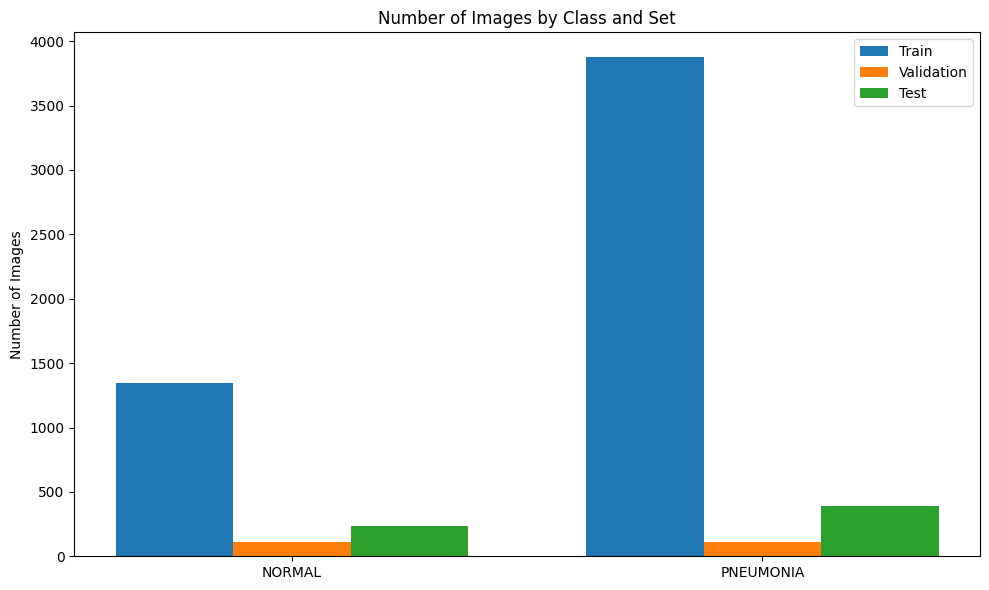

In [ ]:
# Class names
class_names = ['NORMAL', 'PNEUMONIA']

# Function to count images in directories
def count_images(directory):
    counts = {}
    for class_name in class_names:
        class_path = os.path.join(directory, class_name)
        counts[class_name] = len(os.listdir(class_path))
    return counts

# Check if directories exist
print(f"Train directory exists: {os.path.exists(train_dir)}")
print(f"Validation directory exists: {os.path.exists(val_dir)}")
print(f"Test directory exists: {os.path.exists(test_dir)}")

train_counts = count_images(train_dir)
val_counts = count_images(val_dir)
test_counts = count_images(test_dir)

print("\n--- Dataset Distribution ---")
print(f"Train set: {train_counts}")
print(f"Validation set: {val_counts}")
print(f"Test set: {test_counts}")

# Visualize class distribution (e.g., bar plot)
labels = class_names
train_values = [train_counts[label] for label in labels]
val_values = [val_counts[label] for label in labels]
test_values = [test_counts[label] for label in labels]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
# Corrected plot labels to be dynamic
rects1 = ax.bar(x - width, train_values, width, label='Train')
rects2 = ax.bar(x, val_values, width, label='Validation')
rects3 = ax.bar(x + width, test_values, width, label='Test')

ax.set_ylabel('Number of Images')
ax.set_title('Number of Images by Class and Set')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.show()


--- Sample Images from train ---


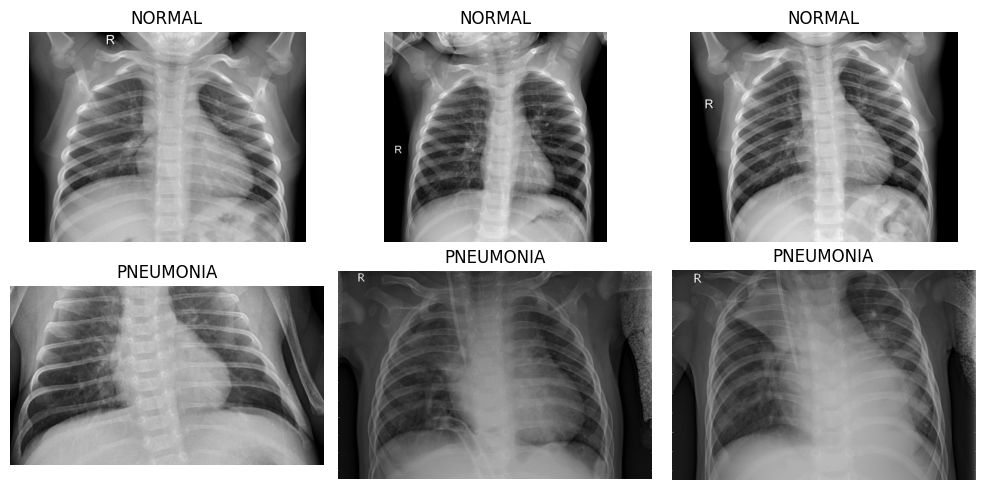

In [ ]:
# Visualize sample images
def display_samples(directory, num_samples=3):
    print(f"\n--- Sample Images from {os.path.basename(directory)} ---")
    plt.figure(figsize=(10, 5))
    for i, class_name in enumerate(class_names):
        class_path = os.path.join(directory, class_name)
        # Handle cases where a directory might be empty
        try:
            sample_images = os.listdir(class_path)[:num_samples]
        except FileNotFoundError:
            print(f"Warning: Directory {class_path} not found.")
            continue

        for j, img_name in enumerate(sample_images):
            img_path = os.path.join(class_path, img_name)
            # Ensure images are in RGB format for consistency
            img = Image.open(img_path).convert('RGB')
            plt.subplot(len(class_names), num_samples, i * num_samples + j + 1)
            plt.imshow(img) # Removed cmap='gray' for consistency with model input
            plt.title(f"{class_name}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()

display_samples(train_dir)

In [ ]:
# --- 2. Data Preprocessing ---
from tensorflow.keras.optimizers import Adam

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# Data Augmentation and Preprocessing for Training
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

# Preprocessing for Validation and Test (no augmentation)
val_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input
)

# Load data from directories (with corrected color_mode)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb'  # Corrected to ensure 3-channel input
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb'  # Corrected to ensure 3-channel input
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False, # Keep data in order for evaluation
    color_mode='rgb'  # Corrected to ensure 3-channel input
)

# Calculate class weights for imbalance
counter = train_generator.classes
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(counter),
    y=counter
)
class_weights_dict = dict(enumerate(class_weights))
print(f"Calculated Class Weights: {class_weights_dict}")

Found 5218 images belonging to 2 classes.
Found 224 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Calculated Class Weights: {0: np.float64(1.9426656738644825), 1: np.float64(0.6732903225806451)}


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
164/164 ━━━━━━━━━━━━━━━━━━━━ 1553s 9s/step - accuracy: 0.8259 - auc: 0.9083 - loss: 0.4010 - precision: 0.9385 - recall: 0.8188 - val_accuracy: 0.9420 - val_auc: 0.9827 - val_loss: 0.2091 - val_precision: 0.9714 - val_recall: 0.9107
Epoch 2/15
164/164 ━━━━━━━━━━━━━━━━━━━━ 495s 3s/step - accuracy: 0.9149 - auc: 0.9739 - loss: 0.2051 - precision: 0.9773 - recall: 0.9084 - val_accuracy: 0.9554 - val_auc: 0.9910 - val_loss: 0.1569 - val_precision: 0.9904 - val_recall: 0.9196
Epoch 3/15
164/164 ━━━━━━━━━━━━━━━━━━━━ 500s 3s/step - accuracy: 0.9248 - auc: 0.9813 - loss: 0.1765 - precision: 0.9808 - recall: 0.9161 - val_accuracy: 0.9643 - val_auc: 0.9942 - val_loss: 0.1304 - val_precision: 1.0000 - val_recall: 0.9286
Epoch 4/15
164/164 ━━━━━━━━━━━━━━━━━━━━ 500s 3s/step - accuracy: 0.9286 - auc: 0.9820 - loss: 0.1669 - precision: 0.9835 - recall: 0.9202 - val_accuracy: 0.9598 - val_auc: 0.9959 - val_loss: 0.1262 - val_precision: 1.0000 - val_recall: 0.9196
Epoch 5/15
164/164 ━━━━━━━━

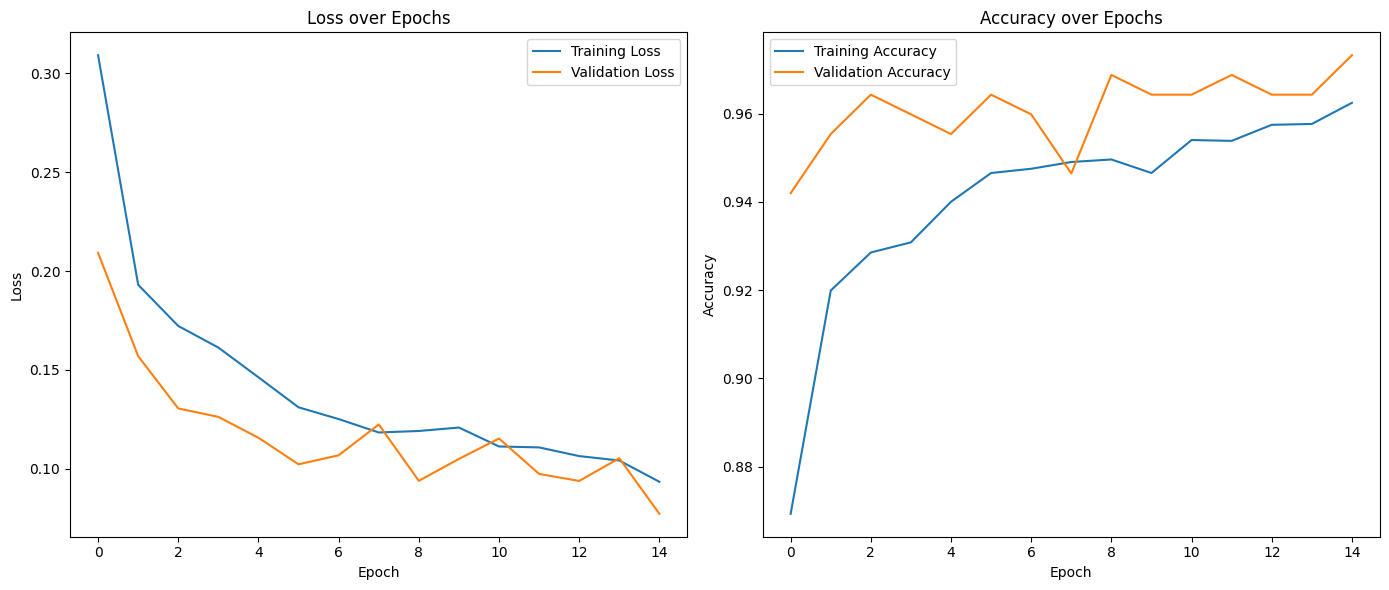

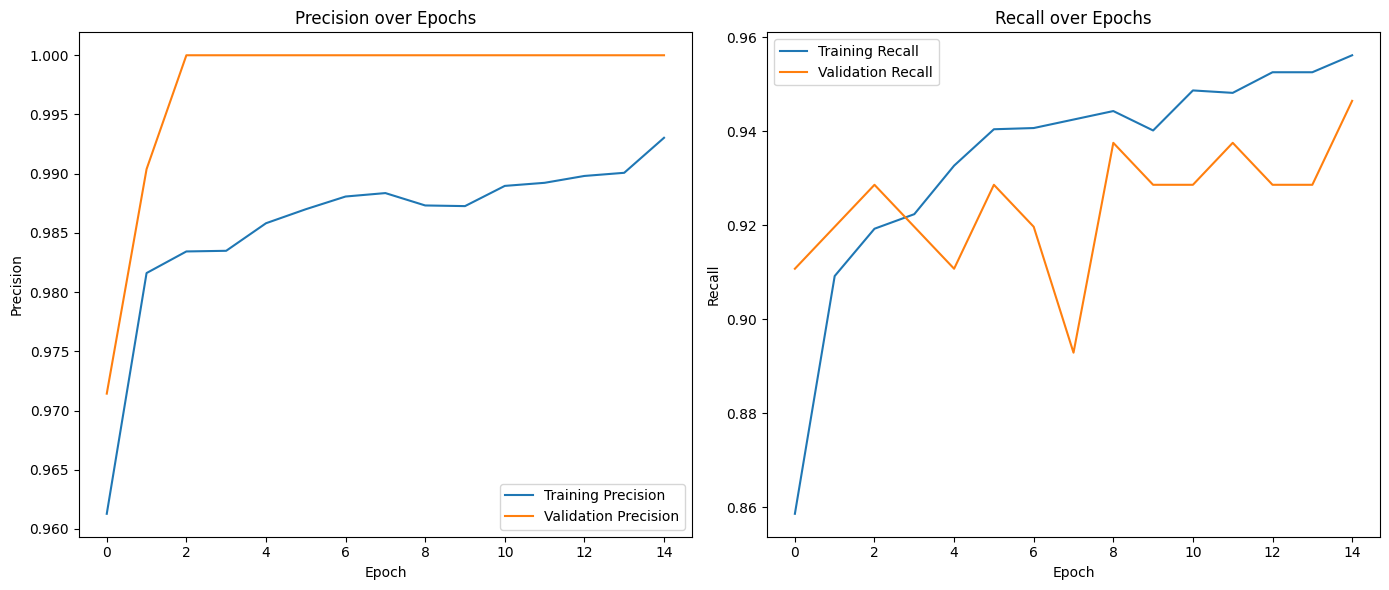

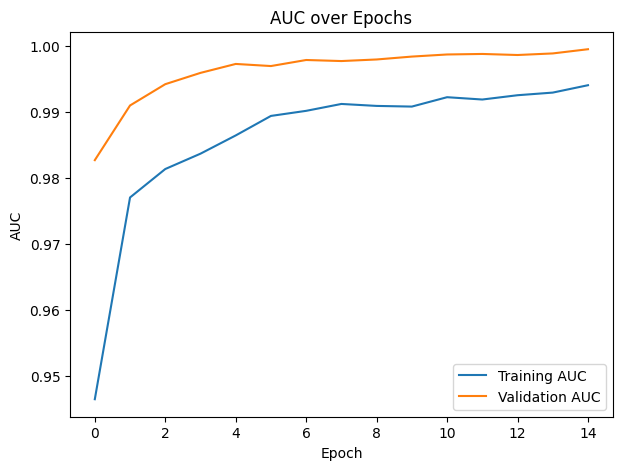

In [ ]:
# --- 3. Model Building & Training ---
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load EfficientNetB0 with pre-trained ImageNet weights
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Fine-tuning strategy: First, freeze the base model
base_model.trainable = False

# Add a custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.summary()

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

# Define callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, monitor='val_loss', restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('pneumonia_detection_efficientnet.keras', save_best_only=True, monitor='val_loss')
]

# Train the model
EPOCHS = 15
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    class_weight=class_weights_dict,
    callbacks=callbacks
)

# Plot training and validation loss and accuracy
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Plot other metrics
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['precision'], label='Training Precision')
plt.plot(history.history['val_precision'], label='Validation Precision')
plt.title('Precision over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['recall'], label='Training Recall')
plt.plot(history.history['val_recall'], label='Validation Recall')
plt.title('Recall over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(history.history['auc'], label='Training AUC')
plt.plot(history.history['val_auc'], label='Validation AUC')
plt.title('AUC over Epochs')
plt.xlabel('Epoch')
plt.ylabel('AUC')
plt.legend()
plt.show()


--- Evaluating on Test Set ---


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


20/20 ━━━━━━━━━━━━━━━━━━━━ 175s 9s/step - accuracy: 0.8574 - auc: 0.6455 - loss: 0.3311 - precision: 0.5055 - recall: 0.6375
Test Loss: 0.2408
Test Accuracy: 0.8942
Test Precision: 0.8876
Test Recall: 0.9513
Test AUC: 0.9644
20/20 ━━━━━━━━━━━━━━━━━━━━ 69s 3s/step

--- Classification Report ---
              precision    recall  f1-score   support

      NORMAL       0.91      0.80      0.85       234
   PNEUMONIA       0.89      0.95      0.92       390

    accuracy                           0.89       624
   macro avg       0.90      0.88      0.88       624
weighted avg       0.90      0.89      0.89       624



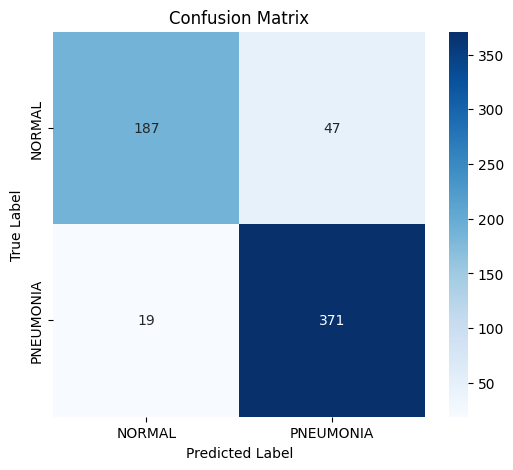

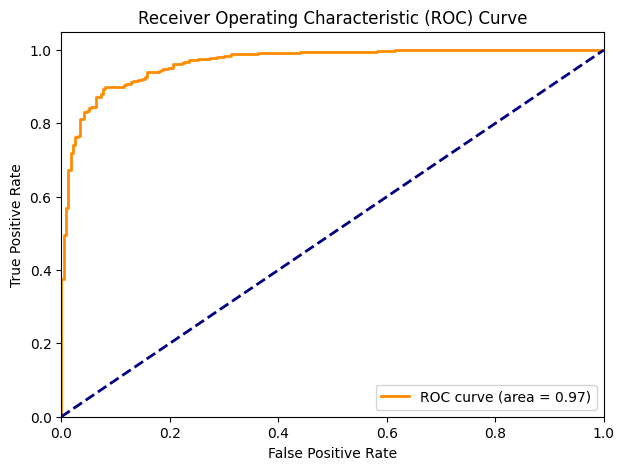

✅ Last Conv Layer: top_conv

--- Grad-CAM for a Normal Image ---


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipython-input-4230607469.py:86: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


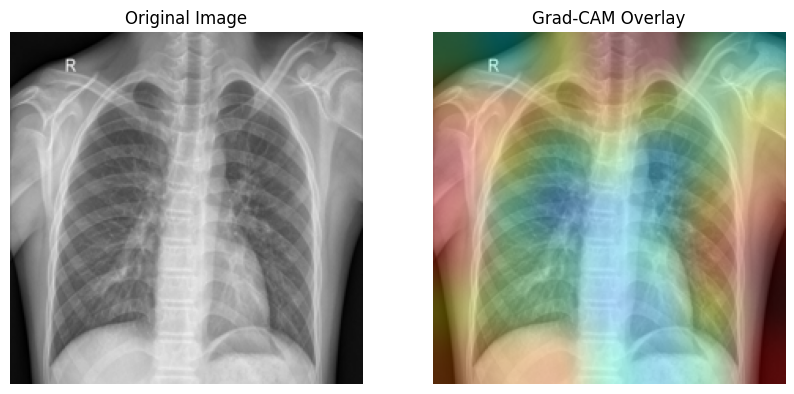


--- Grad-CAM for a Pneumonia Image ---


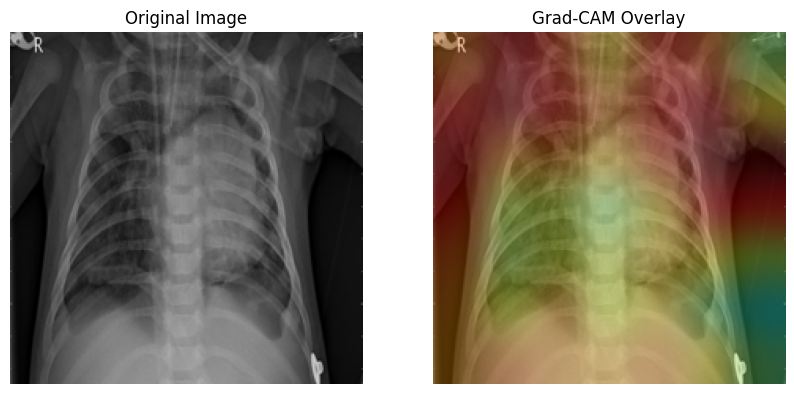

In [43]:
# --- 5. Model Evaluation ---
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

print("\n--- Evaluating on Test Set ---")
test_loss, test_accuracy, test_precision, test_recall, test_auc = model.evaluate(test_generator)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test AUC: {test_auc:.4f}")

test_generator.reset()
Y_pred = model.predict(test_generator)
y_pred_classes = (Y_pred > 0.5).astype(int).flatten()
y_true = test_generator.classes

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

fpr, tpr, thresholds = roc_curve(y_true, Y_pred)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# --- 6. Explainability with Grad-CAM ---
from tensorflow.keras.preprocessing import image
import matplotlib.cm as cm

# Get the last convolutional layer name from EfficientNetB0
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D) or isinstance(layer, tf.keras.layers.DepthwiseConv2D):
        last_conv_layer_name = layer.name
        break

print(f"✅ Last Conv Layer: {last_conv_layer_name}")

# Grad-CAM functions
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, model, last_conv_layer_name, preprocess_input_fn, target_size=(224, 224), alpha=0.4):
    # Load the image and convert to RGB
    img = Image.open(img_path).convert('RGB')
    img = img.resize(target_size)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input_fn(img_array)

    # Get the heatmap
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    jet_heatmap = image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.size[0], img.size[1]))
    jet_heatmap = image.img_to_array(jet_heatmap)

    original_img = image.img_to_array(img)
    superimposed_img = jet_heatmap * alpha + original_img
    superimposed_img = image.array_to_img(superimposed_img)

    # Display the images
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(superimposed_img)
    plt.title("Grad-CAM Overlay")
    plt.axis('off')
    plt.show()

# Example usage for a sample image
sample_normal_path = os.path.join(test_dir, 'NORMAL', os.listdir(os.path.join(test_dir, 'NORMAL'))[0])
sample_pneumonia_path = os.path.join(test_dir, 'PNEUMONIA', os.listdir(os.path.join(test_dir, 'PNEUMONIA'))[0])

print("\n--- Grad-CAM for a Normal Image ---")
display_gradcam(sample_normal_path, model, last_conv_layer_name, preprocess_input)

print("\n--- Grad-CAM for a Pneumonia Image ---")
display_gradcam(sample_pneumonia_path, model, last_conv_layer_name, preprocess_input)

In [45]:
# Save and download in Colab
model_path = '/content/pneumonia_detector_model.h5'
model.save(model_path)

# Download to local system
from google.colab import files
files.download(model_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>